# Netflix Movies and TV Shows Data Analysis

## 1. Project Overview

### Import Libraries

In [30]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

### Load Dataset

In [31]:
movies = pd.read_csv("netflix_titles.csv")

### Data Exploration

#### Preview of Data

In [32]:
movies.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


#### Check dataset dimensions

In [33]:
movies.shape

(8807, 12)

#### Check dataset Information

In [34]:
movies.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8807 non-null   object
 1   type          8807 non-null   object
 2   title         8807 non-null   object
 3   director      6173 non-null   object
 4   cast          7982 non-null   object
 5   country       7976 non-null   object
 6   date_added    8797 non-null   object
 7   release_year  8807 non-null   int64 
 8   rating        8803 non-null   object
 9   duration      8804 non-null   object
 10  listed_in     8807 non-null   object
 11  description   8807 non-null   object
dtypes: int64(1), object(11)
memory usage: 825.8+ KB


#### Summary statistics of data

In [35]:
movies.describe()

,release_year
count,8807.000000
mean,2014.180198
std,8.819312
min,1925.000000
25%,2013.000000
50%,2017.000000
75%,2019.000000
max,2021.000000


### Data Cleaning

In [36]:
movies.isnull().sum()
#Gives the number of missing values in each column

show_id            0
type               0
title              0
director        2634
cast             825
country          831
date_added        10
release_year       0
rating             4
duration           3
listed_in          0
description        0
dtype: int64

In [37]:
movies[movies["rating"].isnull()] 
#shows which netflix titles are missing thier ratings

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
5989,s5990,Movie,13TH: A Conversation with Oprah Winfrey & Ava ...,NaN,"Oprah Winfrey, Ava DuVernay",NaN,"January 26, 2017",2017,NaN,37 min,Movies,Oprah Winfrey sits down with director Ava DuVe...
6827,s6828,TV Show,Gargantia on the Verdurous Planet,NaN,"Kaito Ishikawa, Hisako Kanemoto, Ai Kayano, Ka...",Japan,"December 1, 2016",2013,NaN,1 Season,"Anime Series, International TV Shows","After falling through a wormhole, a space-dwel..."
7312,s7313,TV Show,Little Lunch,NaN,"Flynn Curry, Olivia Deeble, Madison Lu, Oisín ...",Australia,"February 1, 2018",2015,NaN,1 Season,"Kids' TV, TV Comedies","Adopting a child's perspective, this show take..."
7537,s7538,Movie,My Honor Was Loyalty,Alessandro Pepe,"Leone Frisa, Paolo Vaccarino, Francesco Miglio...",Italy,"March 1, 2017",2015,NaN,115 min,Dramas,"Amid the chaos and horror of World War II, a c..."


In [38]:
movies[movies["duration"].isnull()]
##hows which netflix titles are missing their duration

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
5541,s5542,Movie,Louis C.K. 2017,Louis C.K.,Louis C.K.,United States,"April 4, 2017",2017,74 min,NaN,Movies,"Louis C.K. muses on religion, eternal love, gi..."
5794,s5795,Movie,Louis C.K.: Hilarious,Louis C.K.,Louis C.K.,United States,"September 16, 2016",2010,84 min,NaN,Movies,Emmy-winning comedy writer Louis C.K. brings h...
5813,s5814,Movie,Louis C.K.: Live at the Comedy Store,Louis C.K.,Louis C.K.,United States,"August 15, 2016",2015,66 min,NaN,Movies,The comic puts his trademark hilarious/thought...


In [39]:
movies.loc[movies["duration"].isnull(),["title","rating","duration"]]
#.loc is used to display only specfic cols we care about

,title,rating,duration
5541,Louis C.K. 2017,74 min,NaN
5794,Louis C.K.: Hilarious,84 min,NaN
5813,Louis C.K.: Live at the Comedy Store,66 min,NaN


In [40]:
movies.loc[movies["duration"].isnull(), "duration"] = movies["rating"]
movies.loc[movies["duration"].notnull() & movies["rating"].str.contains("min", na=False), "rating"] = None

In [41]:
movies[movies["title"].str.contains("Louis C.",na=False)]

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
5541,s5542,Movie,Louis C.K. 2017,Louis C.K.,Louis C.K.,United States,"April 4, 2017",2017,None,74 min,Movies,"Louis C.K. muses on religion, eternal love, gi..."
5794,s5795,Movie,Louis C.K.: Hilarious,Louis C.K.,Louis C.K.,United States,"September 16, 2016",2010,None,84 min,Movies,Emmy-winning comedy writer Louis C.K. brings h...
5813,s5814,Movie,Louis C.K.: Live at the Comedy Store,Louis C.K.,Louis C.K.,United States,"August 15, 2016",2015,None,66 min,Movies,The comic puts his trademark hilarious/thought...


In [42]:
movies[movies["date_added"].isnull()] 
#Checking if date_added missing values have any patterns besides having nan for date_added column

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
6066,s6067,TV Show,A Young Doctor's Notebook and Other Stories,NaN,"Daniel Radcliffe, Jon Hamm, Adam Godley, Chris...",United Kingdom,NaN,2013,TV-MA,2 Seasons,"British TV Shows, TV Comedies, TV Dramas","Set during the Russian Revolution, this comic ..."
6174,s6175,TV Show,Anthony Bourdain: Parts Unknown,NaN,Anthony Bourdain,United States,NaN,2018,TV-PG,5 Seasons,Docuseries,This CNN original series has chef Anthony Bour...
6795,s6796,TV Show,Frasier,NaN,"Kelsey Grammer, Jane Leeves, David Hyde Pierce...",United States,NaN,2003,TV-PG,11 Seasons,"Classic & Cult TV, TV Comedies",Frasier Crane is a snooty but lovable Seattle ...
6806,s6807,TV Show,Friends,NaN,"Jennifer Aniston, Courteney Cox, Lisa Kudrow, ...",United States,NaN,2003,TV-14,10 Seasons,"Classic & Cult TV, TV Comedies",This hit sitcom follows the merry misadventure...
6901,s6902,TV Show,Gunslinger Girl,NaN,"Yuuka Nanri, Kanako Mitsuhashi, Eri Sendai, Am...",Japan,NaN,2008,TV-14,2 Seasons,"Anime Series, Crime TV Shows","On the surface, the Social Welfare Agency appe..."
7196,s7197,TV Show,Kikoriki,NaN,Igor Dmitriev,NaN,NaN,2010,TV-Y,2 Seasons,Kids' TV,A wacky rabbit and his gang of animal pals hav...
7254,s7255,TV Show,La Familia P. Luche,NaN,"Eugenio Derbez, Consuelo Duval, Luis Manuel Áv...",United States,NaN,2012,TV-14,3 Seasons,"International TV Shows, Spanish-Language TV Sh...","This irreverent sitcom featues Ludovico, Feder..."
7406,s7407,TV Show,Maron,NaN,"Marc Maron, Judd Hirsch, Josh Brener, Nora Zeh...",United States,NaN,2016,TV-MA,4 Seasons,TV Comedies,"Marc Maron stars as Marc Maron, who interviews..."
7847,s7848,TV Show,Red vs. Blue,NaN,"Burnie Burns, Jason Saldaña, Gustavo Sorola, G...",United States,NaN,2015,NR,13 Seasons,"TV Action & Adventure, TV Comedies, TV Sci-Fi ...","This parody of first-person shooter games, mil..."
8182,s8183,TV Show,The Adventures of Figaro Pho,NaN,"Luke Jurevicius, Craig Behenna, Charlotte Haml...",Australia,NaN,2015,TV-Y7,2 Seasons,"Kids' TV, TV Comedies","Imagine your worst fears, then multiply them: ..."


In [43]:
movies[movies["date_added"].isnull()].isnull().sum()

show_id          0
type             0
title            0
director        10
cast             0
country          1
date_added      10
release_year     0
rating           0
duration         0
listed_in        0
description      0
dtype: int64

In [44]:
movies.duplicated().sum()
#zero duplicates

np.int64(0)

### Data Interpretation/ Analysis

In [45]:
movies.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8807 non-null   object
 1   type          8807 non-null   object
 2   title         8807 non-null   object
 3   director      6173 non-null   object
 4   cast          7982 non-null   object
 5   country       7976 non-null   object
 6   date_added    8797 non-null   object
 7   release_year  8807 non-null   int64 
 8   rating        8800 non-null   object
 9   duration      8807 non-null   object
 10  listed_in     8807 non-null   object
 11  description   8807 non-null   object
dtypes: int64(1), object(11)
memory usage: 825.8+ KB


In [46]:
movies.describe()

,release_year
count,8807.000000
mean,2014.180198
std,8.819312
min,1925.000000
25%,2013.000000
50%,2017.000000
75%,2019.000000
max,2021.000000


In [47]:
movies["type"].value_counts()

type
Movie      6131
TV Show    2676
Name: count, dtype: int64

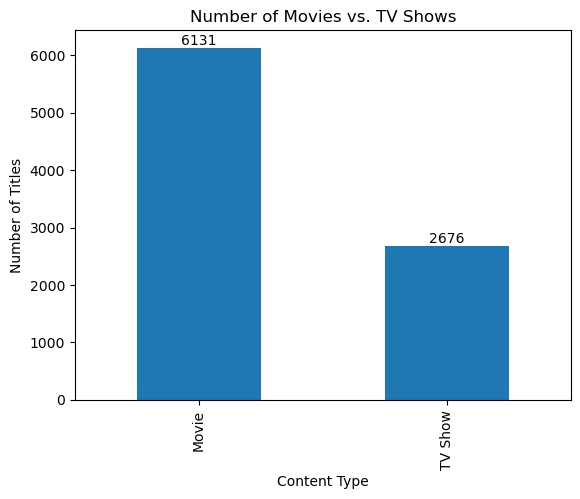

In [49]:
ax = movies["type"].value_counts().plot(kind="bar")

plt.title("Number of Movies vs. TV Shows")
plt.xlabel("Content Type")
plt.ylabel("Number of Titles")

ax.bar_label(ax.containers[0])

plt.show()

In [50]:
movies["country"].head(10)

0                                        United States
1                                         South Africa
2                                                  NaN
3                                                  NaN
4                                                India
5                                                  NaN
6                                                  NaN
7    United States, Ghana, Burkina Faso, United Kin...
8                                       United Kingdom
9                                        United States
Name: country, dtype: object

In [51]:
movies["country"].str.split(", ")

0       [United States]
1        [South Africa]
2                   NaN
3                   NaN
4               [India]
             ...       
8802    [United States]
8803                NaN
8804    [United States]
8805    [United States]
8806            [India]
Name: country, Length: 8807, dtype: object

In [52]:
movies["country"].str.split(", ").explode()

0       United States
1        South Africa
2                 NaN
3                 NaN
4               India
            ...      
8802    United States
8803              NaN
8804    United States
8805    United States
8806            India
Name: country, Length: 10845, dtype: object

In [53]:
movies["country"].str.split(", ").explode().value_counts()

country
United States     3689
India             1046
United Kingdom     804
Canada             445
France             393
                  ... 
Bermuda              1
Ecuador              1
Armenia              1
Mongolia             1
Montenegro           1
Name: count, Length: 127, dtype: int64

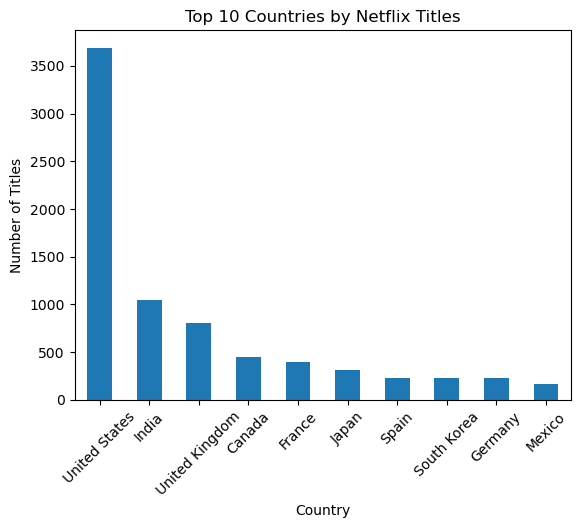

In [54]:
country_counts = movies["country"].str.split(", ").explode().value_counts()

country_counts.head(10).plot(kind="bar")

plt.title("Top 10 Countries by Netflix Titles")
plt.xlabel("Country")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45)
plt.show()

In [55]:
movies["release_year"].value_counts().sort_index()

release_year
1925       1
1942       2
1943       3
1944       3
1945       4
        ... 
2017    1032
2018    1147
2019    1030
2020     953
2021     592
Name: count, Length: 74, dtype: int64

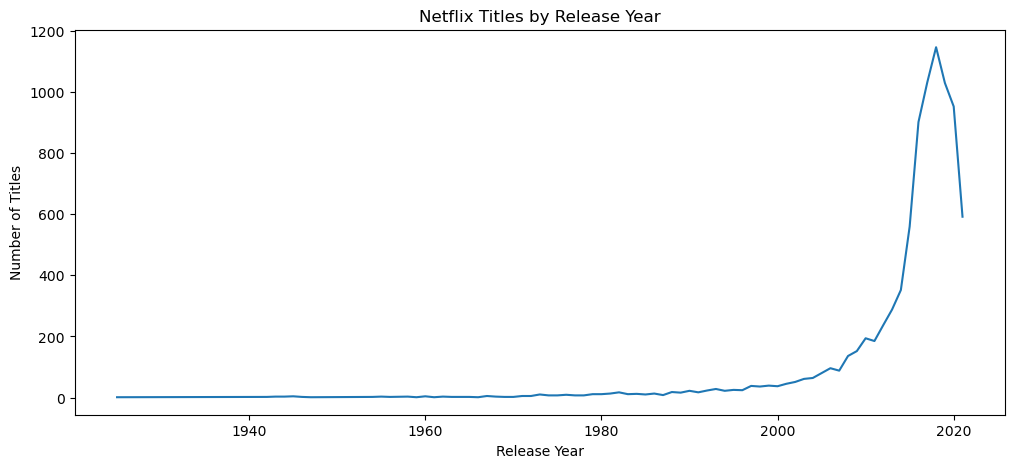

In [56]:
year_counts = movies["release_year"].value_counts().sort_index()

year_counts.plot(kind="line", figsize=(12, 5))

plt.title("Netflix Titles by Release Year")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")
plt.show()

In [57]:
movies["rating"].value_counts()

rating
TV-MA       3207
TV-14       2160
TV-PG        863
R            799
PG-13        490
TV-Y7        334
TV-Y         307
PG           287
TV-G         220
NR            80
G             41
TV-Y7-FV       6
NC-17          3
UR             3
Name: count, dtype: int64

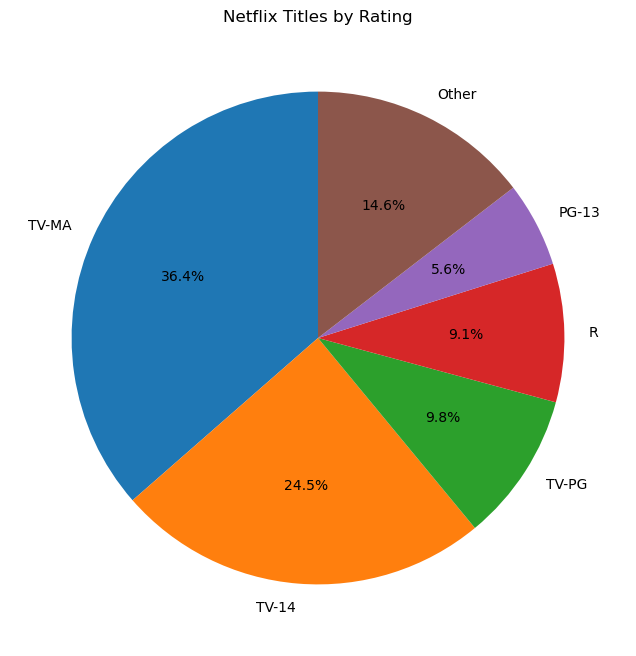

In [60]:
rating_counts = movies["rating"].value_counts()

top_ratings = rating_counts.head(5)
top_ratings["Other"] = rating_counts.iloc[5:].sum()

top_ratings.plot(
    kind="pie",
    figsize=(8, 8),
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Netflix Titles by Rating")
plt.ylabel("")
plt.show()

In [62]:
movie_years = movies[movies["type"] == "Movie"]["release_year"].value_counts().sort_index()
movie_years

release_year
1942      2
1943      3
1944      3
1945      3
1946      1
       ... 
2017    767
2018    767
2019    633
2020    517
2021    277
Name: count, Length: 73, dtype: int64

In [63]:
tv_years = movies[movies["type"] == "TV Show"]["release_year"].value_counts().sort_index()
tv_years

release_year
1925      1
1945      1
1946      1
1963      1
1967      1
1972      1
1974      1
1977      1
1979      1
1981      1
1985      1
1986      2
1988      2
1989      1
1990      3
1991      1
1992      3
1993      4
1994      2
1995      2
1996      3
1997      4
1998      4
1999      7
2000      4
2001      5
2002      7
2003     10
2004      9
2005     13
2006     14
2007     14
2008     23
2009     34
2010     40
2011     40
2012     64
2013     63
2014     88
2015    162
2016    244
2017    265
2018    380
2019    397
2020    436
2021    315
Name: count, dtype: int64

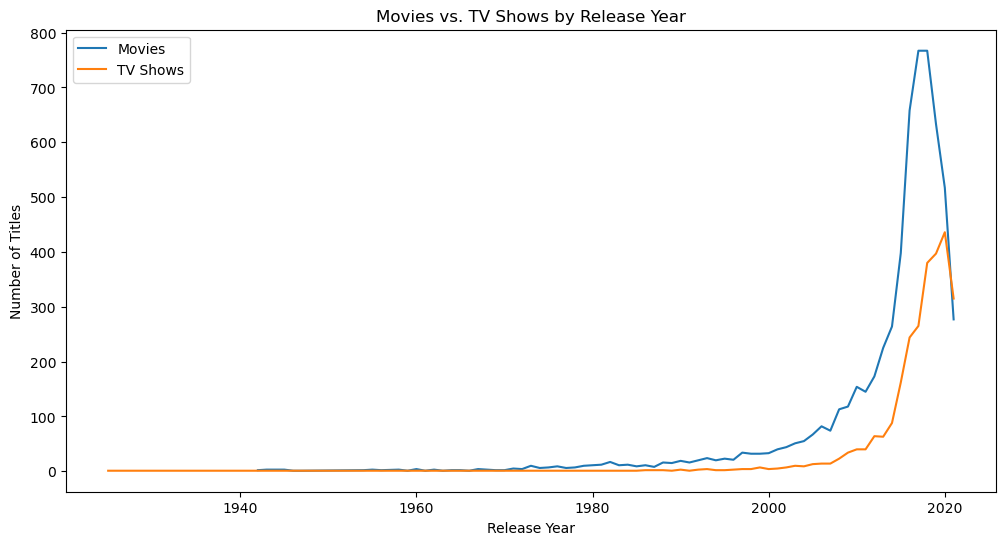

In [64]:
plt.figure(figsize=(12, 6))

plt.plot(movie_years, label="Movies")
plt.plot(tv_years, label="TV Shows")

plt.title("Movies vs. TV Shows by Release Year")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")
plt.legend()

plt.show()

In [65]:
movies[["country", "type", "rating"]].head(10)

,country,type,rating
0,United States,Movie,PG-13
1,South Africa,TV Show,TV-MA
2,NaN,TV Show,TV-MA
3,NaN,TV Show,TV-MA
4,India,TV Show,TV-MA
5,NaN,TV Show,TV-MA
6,NaN,Movie,PG
7,"United States, Ghana, Burkina Faso, United Kin...",Movie,TV-MA
8,United Kingdom,TV Show,TV-14
9,United States,Movie,PG-13


In [67]:
country_data = movies.assign(
    country=movies["country"].str.split(", ")
).explode("country")

country_data[["country", "type", "rating"]].head(10)

,country,type,rating
0,United States,Movie,PG-13
1,South Africa,TV Show,TV-MA
2,NaN,TV Show,TV-MA
3,NaN,TV Show,TV-MA
4,India,TV Show,TV-MA
5,NaN,TV Show,TV-MA
6,NaN,Movie,PG
7,United States,Movie,TV-MA
7,Ghana,Movie,TV-MA
7,Burkina Faso,Movie,TV-MA


In [68]:
country_data = country_data.dropna(subset=["country", "rating"])
country_data.shape

(10008, 12)

In [69]:
top_countries = country_data["country"].value_counts().head(10)

top_countries

country
United States     3686
India             1046
United Kingdom     804
Canada             445
France             393
Japan              317
Spain              232
South Korea        231
Germany            226
Mexico             169
Name: count, dtype: int64

In [71]:
top_country_data = country_data[country_data["country"].isin(top_countries.index)]
top_country_data

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...
7,s8,Movie,Sankofa,Haile Gerima,"Kofi Ghanaba, Oyafunmike Ogunlano, Alexandra D...",United States,"September 24, 2021",1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies","On a photo shoot in Ghana, an American model s..."
7,s8,Movie,Sankofa,Haile Gerima,"Kofi Ghanaba, Oyafunmike Ogunlano, Alexandra D...",United Kingdom,"September 24, 2021",1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies","On a photo shoot in Ghana, an American model s..."
7,s8,Movie,Sankofa,Haile Gerima,"Kofi Ghanaba, Oyafunmike Ogunlano, Alexandra D...",Germany,"September 24, 2021",1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies","On a photo shoot in Ghana, an American model s..."
...,...,...,...,...,...,...,...,...,...,...,...,...
8799,s8800,Movie,Zenda,Avadhoot Gupte,"Santosh Juvekar, Siddharth Chandekar, Sachit P...",India,"February 15, 2018",2009,TV-14,120 min,"Dramas, International Movies",A change in the leadership of a political part...
8802,s8803,Movie,Zodiac,David Fincher,"Mark Ruffalo, Jake Gyllenhaal, Robert Downey J...",United States,"November 20, 2019",2007,R,158 min,"Cult Movies, Dramas, Thrillers","A political cartoonist, a crime reporter and a..."
8804,s8805,Movie,Zombieland,Ruben Fleischer,"Jesse Eisenberg, Woody Harrelson, Emma Stone, ...",United States,"November 1, 2019",2009,R,88 min,"Comedies, Horror Movies",Looking to survive in a world taken over by zo...
8805,s8806,Movie,Zoom,Peter Hewitt,"Tim Allen, Courteney Cox, Chevy Chase, Kate Ma...",United States,"January 11, 2020",2006,PG,88 min,"Children & Family Movies, Comedies","Dragged from civilian life, a former superhero..."


In [72]:
rating_comparison = pd.crosstab(
    [top_country_data["country"], top_country_data["type"]],
    top_country_data["rating"]
)

rating_comparison

rating                   G  NC-17  NR   PG  PG-13    R  TV-14  TV-G  TV-MA  \
country        type                                                          
Canada         Movie     2      1   5   33     32   79     29     8     72   
               TV Show   0      0   0    0      0    0     20     9     35   
France         Movie     2      1   4   21     35   57     45     3    120   
               TV Show   0      0   0    0      0    0      3     3     43   
Germany        Movie     1      0   2    8     31   43     22     6     54   
               TV Show   0      0   0    0      0    0      5     3     25   
India          Movie     0      0   7    7     11    5    547     7    232   
               TV Show   0      0   0    0      0    0     25     3     34   
Japan          Movie     1      0   0   11      9    9     23     0     32   
               TV Show   0      0   0    0      0    0     76     2     69   
Mexico         Movie     0      0   4    2      4   14     12     2     65   
               TV Show   0      0   0    0      0    0     10     1     37   
South Korea    Movie     1      0   4    2      1    2      4     0     37   
               TV Show   0      0   0    0      0    0     82     1     55   
Spain          Movie     3      1   0    4      5   13     14     0    124   
               TV Show   0      0   1    0      0    0      4     1     46   
United Kingdom Movie     4      0  10   35     84  145     58    10    136   
               TV Show   0      0   2    0      0    0     45    15    115   
United States  Movie    39      1  41  243    433  660    276    47    718   
               TV Show   0      0   2    0      0    0    221    42    382   

rating                  TV-PG  TV-Y  TV-Y7  TV-Y7-FV  UR  
country        type                                       
Canada         Movie       25    25      8         0   0  
               TV Show     14    20     27         1   0  
France         Movie        9     1      3         0   2  
               TV Show      3    20     18         0   0  
Germany        Movie       12     1      2         0   0  
               TV Show      5     2      4         0   0  
India          Movie      133     0     12         1   0  
               TV Show     11     6      5         0   0  
Japan          Movie       28     1      5         0   0  
               TV Show     22     2     27         0   0  
Mexico         Movie        5     0      3         0   0  
               TV Show      7     0      3         0   0  
South Korea    Movie        4     1      5         0   0  
               TV Show     15     8      9         0   0  
Spain          Movie        4     2      1         0   0  
               TV Show      6     3      0         0   0  
United Kingdom Movie       41     5      3         0   1  
               TV Show     57    29      9         0   0  
United States  Movie      180    52     55         2   1  
               TV Show    124    75     92         0   0

In [75]:
movie_ratings = top_country_data[top_country_data["type"] == "Movie"]
tv_ratings = top_country_data[top_country_data["type"] == "TV Show"]

In [76]:
movie_rating_table = pd.crosstab(
    movie_ratings["country"],
    movie_ratings["rating"]
)

movie_rating_table

rating,G,NC-17,NR,PG,PG-13,R,TV-14,TV-G,TV-MA,TV-PG,TV-Y,TV-Y7,TV-Y7-FV,UR
country,,,,,,,,,,,,,,
Canada,2,1,5,33,32,79,29,8,72,25,25,8,0,0
France,2,1,4,21,35,57,45,3,120,9,1,3,0,2
Germany,1,0,2,8,31,43,22,6,54,12,1,2,0,0
India,0,0,7,7,11,5,547,7,232,133,0,12,1,0
Japan,1,0,0,11,9,9,23,0,32,28,1,5,0,0
Mexico,0,0,4,2,4,14,12,2,65,5,0,3,0,0
South Korea,1,0,4,2,1,2,4,0,37,4,1,5,0,0
Spain,3,1,0,4,5,13,14,0,124,4,2,1,0,0
United Kingdom,4,0,10,35,84,145,58,10,136,41,5,3,0,1


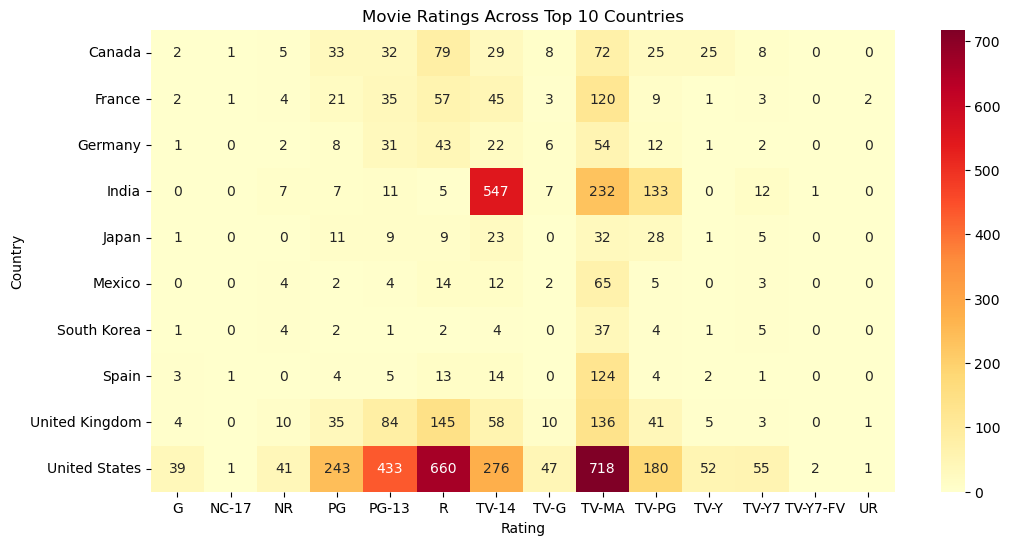

In [77]:
plt.figure(figsize=(12, 6))

sns.heatmap(movie_rating_table, annot=True, fmt="d", cmap="YlOrRd")

plt.title("Movie Ratings Across Top 10 Countries")
plt.xlabel("Rating")
plt.ylabel("Country")
plt.show()

In [78]:
tv_rating_table = pd.crosstab(
    tv_ratings["country"],
    tv_ratings["rating"]
)

tv_rating_table

rating,NR,TV-14,TV-G,TV-MA,TV-PG,TV-Y,TV-Y7,TV-Y7-FV
country,,,,,,,,
Canada,0,20,9,35,14,20,27,1
France,0,3,3,43,3,20,18,0
Germany,0,5,3,25,5,2,4,0
India,0,25,3,34,11,6,5,0
Japan,0,76,2,69,22,2,27,0
Mexico,0,10,1,37,7,0,3,0
South Korea,0,82,1,55,15,8,9,0
Spain,1,4,1,46,6,3,0,0
United Kingdom,2,45,15,115,57,29,9,0


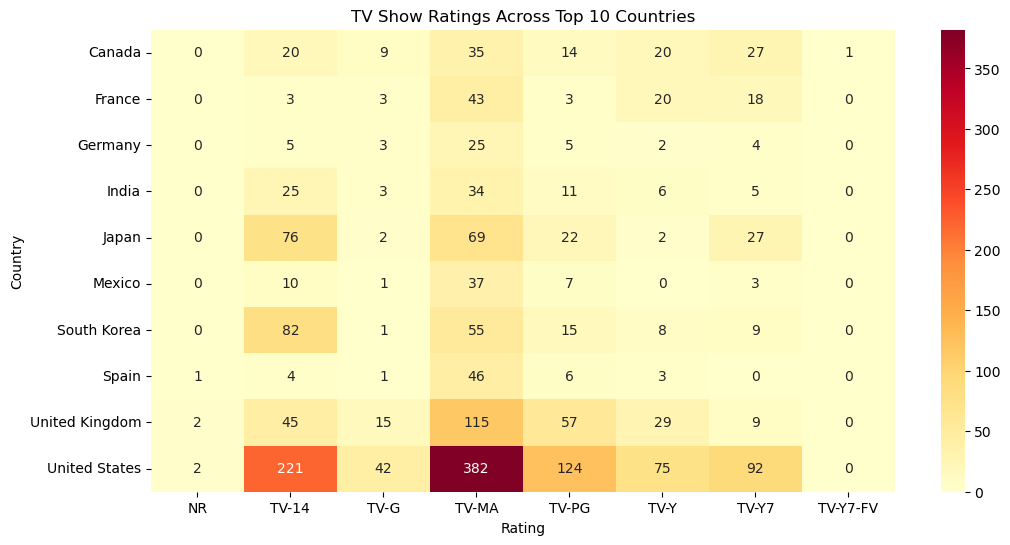

In [79]:
plt.figure(figsize=(12, 6))

sns.heatmap(tv_rating_table, annot=True, fmt="d", cmap="YlOrRd")

plt.title("TV Show Ratings Across Top 10 Countries")
plt.xlabel("Rating")
plt.ylabel("Country")
plt.show()

### Key findings